# 08 V4 — Final diagnostic curves composite

Duplicate-tolerant version. CPU only.

In [1]:

from pathlib import Path
import hashlib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

print("=== V4 DUPLICATE-TOLERANT VERSION ===")

def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def find_preferred(filename):
    hits = [p for p in INPUT_ROOT.rglob(filename) if p.is_file()]
    if not hits:
        raise FileNotFoundError(
            f"Could not find {filename!r} under /kaggle/input."
        )

    if len(hits) == 1:
        print("Found:", filename, "->", hits[0])
        return hits[0]

    # Kaggle can expose duplicated extracted folders, e.g.
    # ".../MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/" and "... (1)/".
    # If duplicates are byte-identical, safely select the cleanest path.
    hashes = {}
    for p in hits:
        hashes.setdefault(_sha256(p), []).append(p)

    if len(hashes) == 1:
        chosen = sorted(
            hits,
            key=lambda p: (
                " (1)" in str(p),
                " (2)" in str(p),
                len(str(p)),
                str(p),
            ),
        )[0]
        print(
            f"Found {len(hits)} identical copies of {filename}; "
            f"using: {chosen}"
        )
        return chosen

    # If copies are not identical, prefer the non-duplicated fixed-input path.
    preferred = [
        p for p in hits
        if "MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED" in str(p)
        and " (1)" not in str(p)
        and " (2)" not in str(p)
    ]
    if len(preferred) == 1:
        print(
            f"Warning: multiple non-identical copies of {filename}; "
            f"using the canonical fixed-input path: {preferred[0]}"
        )
        return preferred[0]

    raise RuntimeError(
        f"Found multiple non-identical copies of {filename!r}: {hits}. "
        "Please attach only one presentation-input dataset."
    )

def load_rgb(filename):
    return Image.open(find_preferred(filename)).convert("RGB")


=== V4 DUPLICATE-TOLERANT VERSION ===


In [2]:

required = [
    "Figure13_OOF_precision_recall_curves.png",
    "Figure14_OOF_ROC_curves.png",
    "Figure15_OOF_reliability_diagram.png",
    "Figure_locked_test_baseline_comparison.png",
]
for name in required:
    find_preferred(name)

print("\nInput check PASSED.")


Found 2 identical copies of Figure13_OOF_precision_recall_curves.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure13_OOF_precision_recall_curves.png
Found 2 identical copies of Figure14_OOF_ROC_curves.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure14_OOF_ROC_curves.png
Found 2 identical copies of Figure15_OOF_reliability_diagram.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure15_OOF_reliability_diagram.png
Found 2 identical copies of Figure_locked_test_baseline_comparison.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/journal/figures/Figure_locked_test_baseline_comparison.png

Input check PASSED.


Found 2 identical copies of Figure13_OOF_precision_recall_curves.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure13_OOF_precision_recall_curves.png
Found 2 identical copies of Figure14_OOF_ROC_curves.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure14_OOF_ROC_curves.png
Found 2 identical copies of Figure15_OOF_reliability_diagram.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/step2/figures/Figure15_OOF_reliability_diagram.png
Found 2 identical copies of Figure_locked_test_baseline_comparison.png; using: /kaggle/input/datasets/saifsamiul/ms3seg-final-presentation-inputs-fixed/MS3SEG_FINAL_PRESENTATION_INPUTS_FIXED/journal/figures/Figure_locked_test_baseline_comparison.png


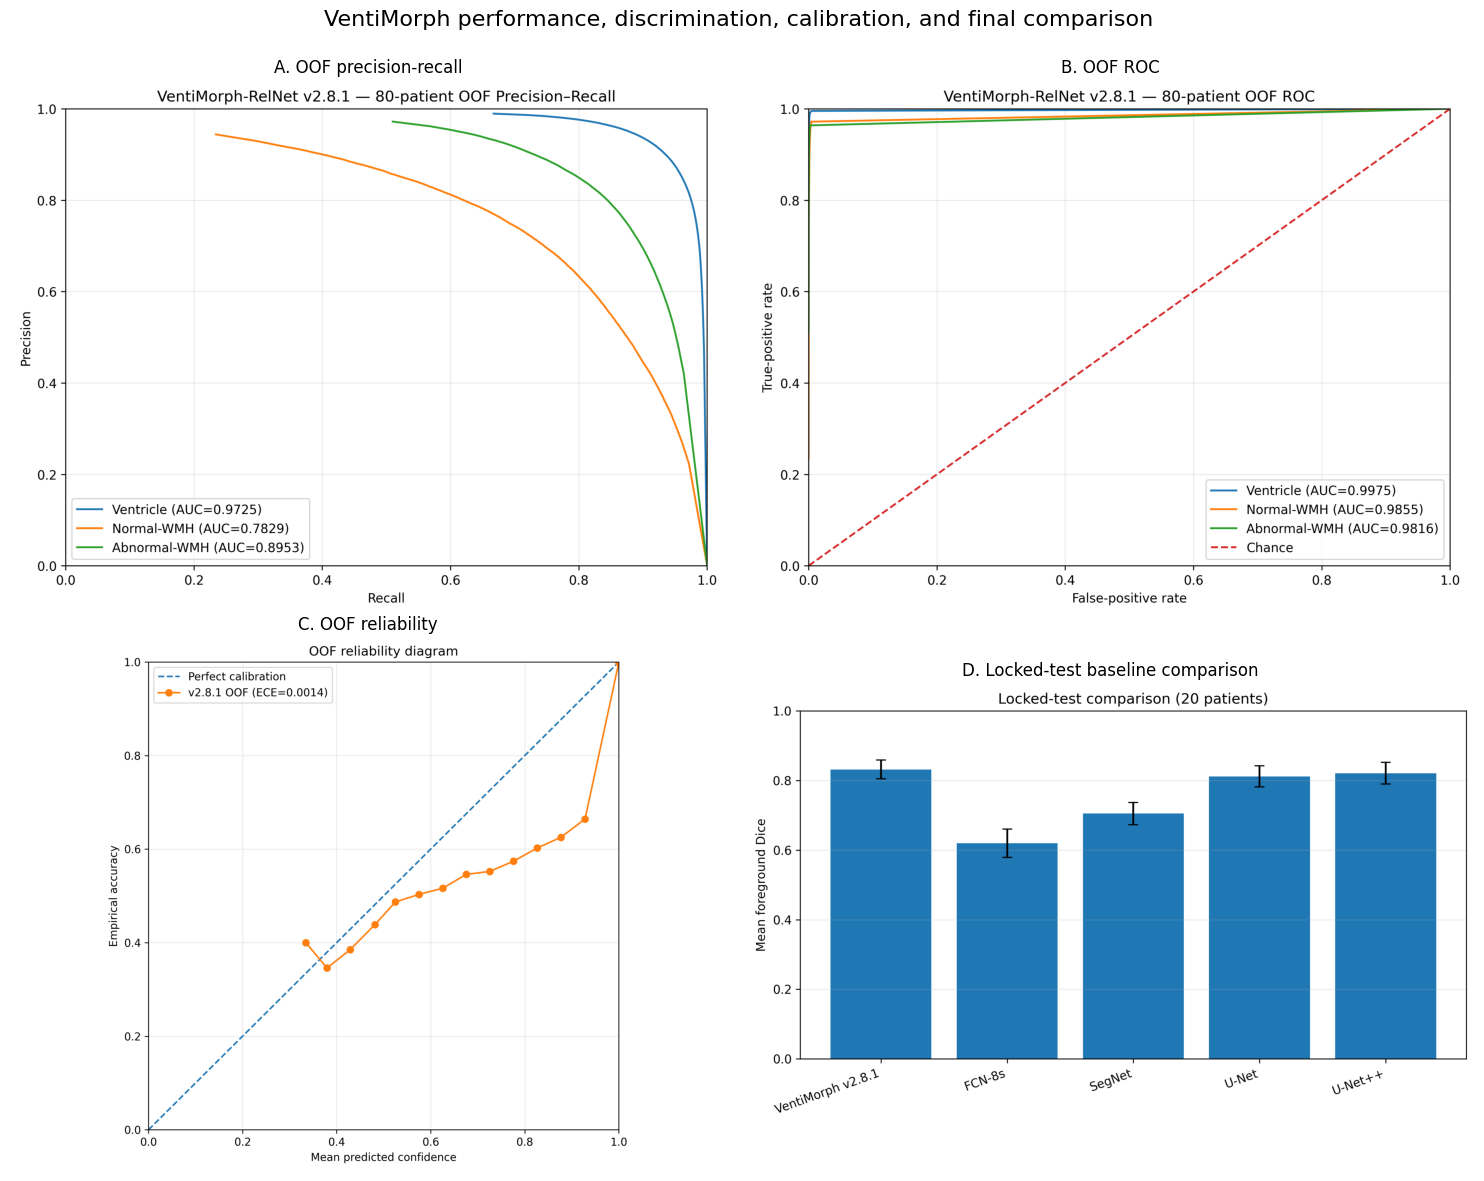

Download: /kaggle/working/MS3SEG_FINAL_DIAGNOSTIC_COMPOSITE_V4.zip


In [3]:

OUT = WORK_ROOT / "final_diagnostic_composite_v4"
OUT.mkdir(parents=True, exist_ok=True)

panels = [
    ("A. OOF precision-recall", load_rgb("Figure13_OOF_precision_recall_curves.png")),
    ("B. OOF ROC", load_rgb("Figure14_OOF_ROC_curves.png")),
    ("C. OOF reliability", load_rgb("Figure15_OOF_reliability_diagram.png")),
    ("D. Locked-test baseline comparison", load_rgb("Figure_locked_test_baseline_comparison.png")),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (title, img) in zip(axes.flat, panels):
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=12)

fig.suptitle(
    "VentiMorph performance, discrimination, calibration, and final comparison",
    fontsize=16,
)
fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(OUT / "Figure_diagnostic_performance_composite.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "Figure_diagnostic_performance_composite.pdf", bbox_inches="tight")
plt.show()

archive = shutil.make_archive(
    "/kaggle/working/MS3SEG_FINAL_DIAGNOSTIC_COMPOSITE_V4",
    "zip",
    root_dir=OUT,
)
print("Download:", archive)
